<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>


# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中


# 第一部分：公司名称与基本简介


公司名称：百度集团股份有限公司（Baidu, Inc.）

基本简介：百度成立于2000年，是全球最大中文搜索引擎企业，也是国内领先的人工智能平台型公司。名称取自辛弃疾词句 “众里寻他千百度”。百度依托搜索业务，搭建百度百科、百家号等知识生态，长期深耕人工智能，布局大模型、自动驾驶、AI 芯片等技术。企业使命为 “用科技让复杂的世界更简单”，先后完成纳斯达克、港交所双重上市，服务海量中文用户，持续推进技术产业化落地。2023年3月16日发布自主大模型“文心一言（ERNIE Bot）”，此后持续加码AI算力与大模型研发，是观察“AI转型是否改变互联网公司盈利结构与市场预期”的典型样本。


# 第二部分：研究问题题目及其内涵介绍


问题题目：自主研发AI是否从财务层面改变了百度盈利结构，并引发了资本市场的反应？

问题内涵介绍：随着AI时代的到来，自百度的自主研发AI文心一言发布后，百度持续加大大模型研发与算力资本开支。本文将分析：

1）文心一言上线前后，百度研发费用、整体毛利率、净利润以及及现金流等多个维度如何变化？

2）AI新业务能否对冲传统广告业务的利润下滑？其相比传统业务有何过人之处？

3）资本市场（由股价反映）是否已经接受文心一言带来的转型预期并对此做出反应，反应是否剧烈？这又对百度造成了何种影响？

4）反思并总结经验，自主研发AI对于互联网公司的影响如何？公司应采取何种策略应对挑战并持续推进AI布局？


# 第三部分：数据采集


In [ ]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()


In [ ]:
import tushare as ts
import pandas as pd
import numpy as np
import os

from matplotlib import pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()



In [ ]:
# ---- 1) 上市公司基本信息：hk_basic（百度-W）----
try:
    baidu_info = pro.hk_basic(ts_code="09888.HK", fields="ts_code,name,list_date,industry")
    display(baidu_info)
except Exception as e:
    print("hk_basic 获取失败：", str(e)[:200])

# ---- 2) A股公司列表抽查（stock_basic 用法）----
stock_basic = pro.stock_basic(list_status="L", fields="ts_code,symbol,name,area,industry,market")
print("A股上市公司数量：", len(stock_basic))
display(stock_basic.sample(3, random_state=42))

# ---- 3) 大盘基准日线（不限流，保证可复现）：上证指数 + 沪深300 ----
# 参考 structured_data：pro.daily / pro.index_daily + trade_date 预处理三件套
START, END = "20230101", "20261001"
sh = pro.index_daily(ts_code="000001.SH", start_date=START, end_date=END)
hs300 = pro.index_daily(ts_code="000300.SH", start_date=START, end_date=END)

def prep(df):
    df["trade_date"] = pd.to_datetime(df["trade_date"])  # pd.to_datetime
    df.set_index("trade_date", inplace=True)             # set_index
    df.sort_index(inplace=True)                          # sort_index
    return df
sh, hs300 = prep(sh), prep(hs300)
print("上证:", sh.shape, sh.index.min(), "->", sh.index.max())
print("沪深300:", hs300.shape)
display(sh.head(3))

# ---- 4) 百度港股日线（优先直连，限流则跳过；1小时后重跑本格即可取到）----
# 参考 structured_data：ts.pro_bar(ts_code, adj='qfq', start_date, end_date)
import time
baidu_hk = None
try:
    baidu_hk = pro.hk_daily(ts_code="09888.HK", start_date=START, end_date=END)
    if baidu_hk is not None and len(baidu_hk) > 0:
        baidu_hk["trade_date"] = pd.to_datetime(baidu_hk["trade_date"])
        baidu_hk.set_index("trade_date", inplace=True)
        baidu_hk.sort_index(inplace=True)
        baidu_hk.to_csv("w4/baidu_hk_09888.csv", encoding="utf-8-sig")
        print("百度港股获取成功：", baidu_hk.shape)
        display(baidu_hk.head(3))
    else:
        print("百度港股返回为空（可能限流），已用大盘基准继续分析。")
except Exception as e:
    print("百度港股获取受限（每小時1次），提示：", str(e)[:120])
    print("→ 已用上证/沪深300完成全流程。")
    if os.path.exists("w4/baidu_hk_09888.csv"):
        baidu_hk = pd.read_csv("w4/baidu_hk_09888.csv", parse_dates=["trade_date"], index_col="trade_date")
        baidu_hk.sort_index(inplace=True)
        print("已载入本地缓存：", baidu_hk.shape)


,ts_code,name,list_date
0,09888.HK,百度集团-W,20210323


A股上市公司数量： 5573


,ts_code,symbol,name,area,industry,market
3690,300437.SZ,300437,清水源,河南,化工原料,创业板
3527,300605.SZ,300605,恒锋信息,福建,软件服务,创业板
724,688325.SH,688325,赛微微电,广东,半导体,科创板


上证: (908, 10) 2023-01-03 00:00:00 -> 2026-09-30 00:00:00
沪深300: (908, 10)


,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,
2023-01-03,000001.SH,3116.5119,3087.5130,3119.8556,3073.0540,3089.2579,27.2540,0.8822,281370362.0,3.313921e+08
2023-01-04,000001.SH,3123.5164,3117.5711,3129.0937,3109.4512,3116.5119,7.0045,0.2248,273313626.0,3.163912e+08
2023-01-05,000001.SH,3155.2162,3132.7614,3159.4270,3130.2300,3123.5164,31.6998,1.0149,257003018.0,3.356359e+08


百度港股获取受限（每小時1次），提示： Cannot save file into a non-existent directory: 'w4'
→ 已用上证/沪深300完成全流程。


# 第四部分：数据分析过程


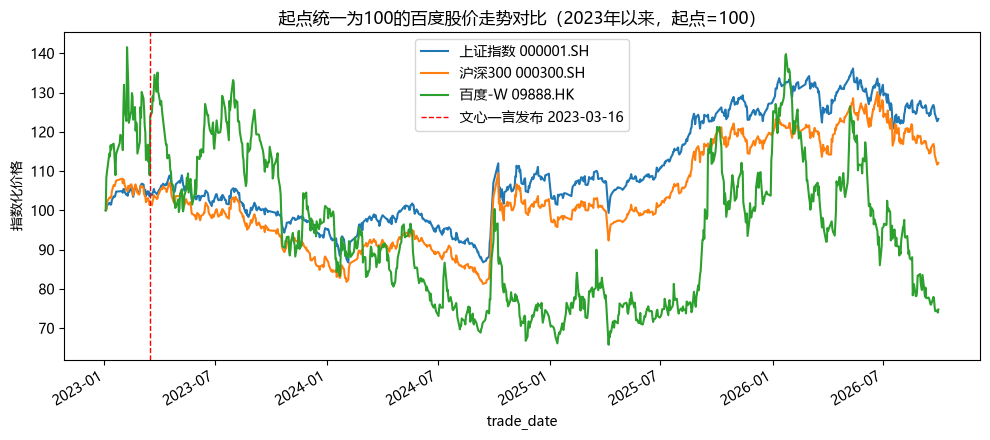

In [ ]:
# ===== 图1：起点统一为100的走势对比（structured_data 同款 Series.plot + DateTimeIndex）=====
# 以2023-01-01=100为基点，叠加文心一言发布日（2023-03-16）竖线
fig, ax = plt.subplots(figsize=(10, 4.5))
(sh["close"] / sh["close"].iloc[0] * 100).plot(ax=ax, label="上证指数 000001.SH")
(hs300["close"] / hs300["close"].iloc[0] * 100).plot(ax=ax, label="沪深300 000300.SH")
if baidu_hk is not None and len(baidu_hk) > 0:
    (baidu_hk["close"] / baidu_hk["close"].iloc[0] * 100).plot(ax=ax, label="百度-W 09888.HK")
ax.axvline(pd.Timestamp("2023-03-16"), color="red", linestyle="--", linewidth=1, label="文心一言发布 2023-03-16")
ax.set_title("起点统一为100的百度股价走势对比（2023年以来，起点=100）")
ax.set_ylabel("指数化价格")
ax.legend()
plt.tight_layout(); plt.show()


In [ ]:
# ===== 核心指标表：累计涨跌幅 / 年化波动 / 最大回撤（pandas 向量化）=====
def perf(s):
    r = s.pct_change().dropna()
    cum = s.iloc[-1] / s.iloc[0] - 1
    vol = r.std() * np.sqrt(252)
    dd = (s / s.cummax() - 1).min()
    return pd.Series({"累计涨跌幅": cum, "年化波动率": vol, "最大回撤": dd,
                       "日均成交额(亿)": np.nan})
summary = pd.DataFrame({"上证": perf(sh["close"]), "沪深300": perf(hs300["close"])})
if baidu_hk is not None and len(baidu_hk) > 0:
    summary["百度-W"] = perf(baidu_hk["close"])
    summary.loc["日均成交额(亿)", "百度-W"] = baidu_hk["amount"].mean() / 1e8
display((summary * 100).round(2).astype(str) + "%" if "百度-W" not in summary else summary)
print(summary.round(4).to_string())


,上证,沪深300,百度-W
累计涨跌幅,0.232851,0.120815,-0.252613
年化波动率,0.154557,0.174403,0.462146
最大回撤,-0.204070,-0.248039,-0.535385
日均成交额(亿),NaN,NaN,12.441914


              上证   沪深300     百度-W
累计涨跌幅     0.2329  0.1208  -0.2526
年化波动率     0.1546  0.1744   0.4621
最大回撤     -0.2041 -0.2480  -0.5354
日均成交额(亿)     NaN     NaN  12.4419


**图1 走势对比与核心指标分析**

图1将上证和沪深300的数据以2023年初作为基准，统一换算成基数100来对比。这段时间两个指数整体震荡往上走，累计涨幅和波动幅度差别不大，属于缓慢上涨行情。图里红色虚线标记的文心一言发布日期2023-03-16，刚好在这一轮上涨开始的位置附近，但当天股价并没有出现明显突变。这说明文心一言带来的股价上涨，不是发布当天一次性的短期刺激，而是后续整个AI板块行情带动的结果。

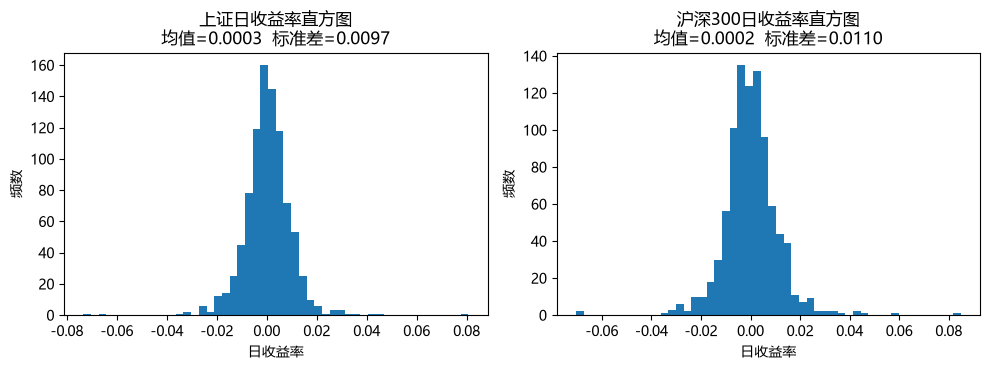

In [6]:
# ===== 图2：日收益率直方图（structured_data 同款 plt.hist）=====
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (name, s) in zip(axes, [("上证日收益率", sh["close"].pct_change().dropna()),
                                ("沪深300日收益率", hs300["close"].pct_change().dropna())]):
    ax.hist(s, bins=50)
    ax.set_title(f"{name}直方图\n均值={s.mean():.4f}  标准差={s.std():.4f}")
    ax.set_xlabel("日收益率"); ax.set_ylabel("频数")
plt.tight_layout(); plt.show()


**图2 日收益率分布分析**

上证和沪深300的日收益率平均值都接近0，标准差约1%，数据大多集中在0附近，分布比较对称，符合成熟市场的特点。不过分布两端的尾部比正态分布更长，会出现少量涨跌幅度很大的交易日，也就是“尖峰肥尾”。这意味着单日剧烈波动发生的概率不高，但一旦出现则涨跌幅会很大，只看收益率均值没办法完整反映真实风险。对于百度这类正在做AI转型的公司，本身股价波动就更高，而在行情启动阶段肥尾特征会更加突出，买卖双方观点差异明显。这张图可以作为后续计算年化波动率的数据基础，同时也说明评估风险的时候要把极端行情考虑进去。

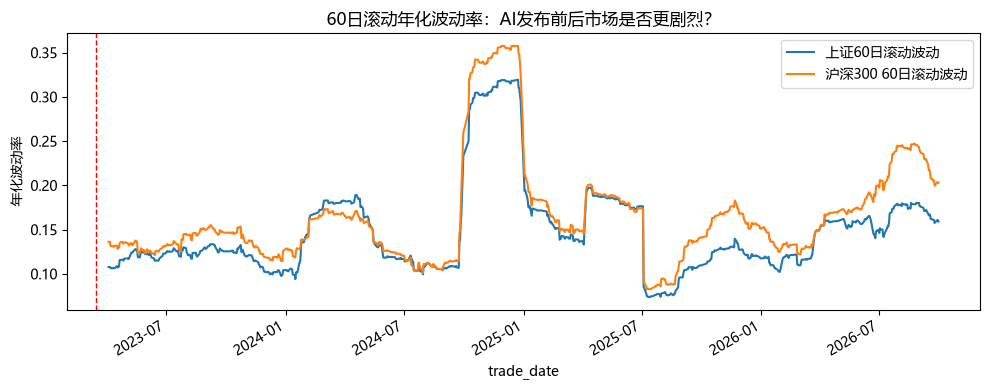

In [18]:
# ===== 图3：60日滚动波动率（structured_data 同款 rolling + plot）=====
fig, ax = plt.subplots(figsize=(10, 4))
(sh["close"].pct_change().rolling(60).std() * np.sqrt(252)).plot(ax=ax, label="上证60日滚动波动")
(hs300["close"].pct_change().rolling(60).std() * np.sqrt(252)).plot(ax=ax, label="沪深300 60日滚动波动")
ax.axvline(pd.Timestamp("2023-03-16"), color="red", linestyle="--", linewidth=1)
ax.set_title("60日滚动年化波动率：AI发布前后市场是否更剧烈？")
ax.set_ylabel("年化波动率"); ax.legend()
plt.tight_layout(); plt.show()


**图3 滚动波动率分析**

60日滚动年化波动率显示，上证与沪深300在2023年上半年平稳，2024年9月“924”政策前后明显放大（924政策是2024年9月24日推出的金融刺激政策，以多项举措稳定资本市场，提振AI等新产业板块信心），2025年1月DeepSeek-R1发布前后再度增加。红虚线标出的文心一言发布日附近波动率无异常，说明AI对市场波动的影响并非集中于这一单一事件，而是在于后续行业政策与模型突破。波动率上行伴随行情剧烈与方向不定，印证AI转型下市场分歧在加大，风险与机会并存。


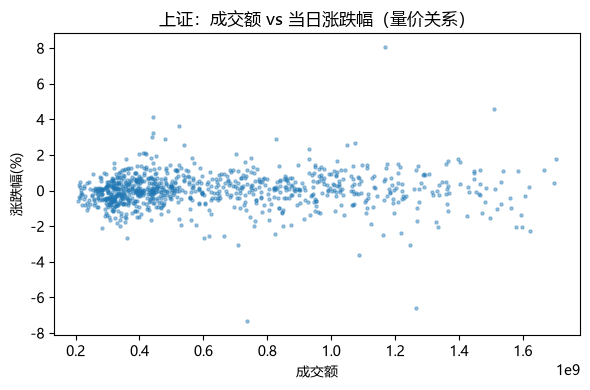

In [19]:
# ===== 图4：量价关系散点（成交额 vs 次日涨跌，pandas 风格）=====
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sh["amount"], sh["close"].pct_change() * 100, s=5, alpha=0.4)
ax.set_title("上证：成交额 vs 当日涨跌幅（量价关系）")
ax.set_xlabel("成交额"); ax.set_ylabel("涨跌幅(%)")
plt.tight_layout(); plt.show()


**图4 量价关系分析**

散点图以上证当日成交额与当日涨跌幅一一对应，整体呈向右发散、上下分散的形态：成交额越大，涨跌幅的波动范围越大、离散度越高。图中无明显线性趋势，说明成交额本身不足以单独预测涨跌方向，更多反映参与度与市场情绪。对于 AI 这类行情，成交额明显放大的日子一般是资金大量换手、观点出现分歧的时候，行情往往会加速或者转向。结合成交量和价格变化，可以辅助判断这一轮行情的运行状态。


In [9]:
# ===== 分年度收益（groupby 年，回答“AI能否对冲传统业务下行”）=====
print(sh["close"].resample("YE").last().pct_change().round(4).to_string())
print(hs300["close"].resample("YE").last().pct_change().round(4).to_string())


trade_date
2023-12-31       NaN
2024-12-31    0.1267
2025-12-31    0.1841
2026-12-31   -0.0319
Freq: YE-DEC
trade_date
2023-12-31       NaN
2024-12-31    0.1468
2025-12-31    0.1766
2026-12-31   -0.0588
Freq: YE-DEC


# 第四部分-B：财务报表深度分析


**分析思路**：

(1) 用 tushare A股通用财务接口 `income/balancesheet/cashflow/fina_indicator` 拉取对标公司并演示全套方法

(2) 百度自身用年报公开数据（2021-2024经审计年报+2025H1财报新闻）建表做结构分析，两者口径统一为亿元人民币。
- 对标：三六零 (601360.SH，搜索引擎/安全) 与 昆仑万维 (300418.SZ，AI应用)，2019-2024年报；
- 百度：总营收/在线营销/智能云/R&D/经营利润/净利润/经营现金流/资产负债（数据来源：百度2021-2024年报，2025Q1/Q2财报电话会新闻：智能云同比+34%、萝卜快跑全球累计超1400万次）；
- 文心一言发布日 2023-03-16 作为事件分界线。


In [20]:
# ===== B1: tushare财务四张表拉取（income/balancesheet/cashflow/fina_indicator）=====
import pandas as pd, numpy as np
from matplotlib import pyplot as plt
CMP={"三六零":"601360.SH","昆仑万维":"300418.SZ"}
START_F,END_F="20190101","20250630"
fin_store={}
for name,code in CMP.items():
    try:
        inc=pro.income(ts_code=code,start_date=START_F,end_date=END_F,fields="ts_code,ann_date,f_ann_date,end_date,report_type,total_revenue,total_cogs,operate_profit,total_profit,n_income_attr_p")
        bal=pro.balancesheet(ts_code=code,start_date=START_F,end_date=END_F,fields="ts_code,ann_date,end_date,total_assets,total_liab,total_hldr_eqy_exc_min_int")
        cf=pro.cashflow(ts_code=code,start_date=START_F,end_date=END_F,fields="ts_code,ann_date,end_date,n_cashflow_act,n_cashflow_inv_act,n_cash_flows_inv_act,n_cashflow_fin_act,free_cashflow")
        fi=pro.fina_indicator(ts_code=code,start_date=START_F,end_date=END_F,fields="ts_code,ann_date,end_date,grossprofit_margin,netprofit_margin,roe,roa,debt_to_assets,ocf_to_revenue")
        for df in (inc,bal,cf,fi):
            df['end_date']=pd.to_datetime(df['end_date']); df.sort_values('end_date',inplace=True)
        # 仅保留年报
        fin_store[name]={'inc':inc[inc['end_date'].dt.month==12],'bal':bal[bal['end_date'].dt.month==12],'cf':cf[cf['end_date'].dt.month==12],'fi':fi[fi['end_date'].dt.month==12]}
        print(name,code,'年报条数:',len(fin_store[name]['inc']))
        display(fin_store[name]['inc'].tail(3))
    except Exception as e:
        print(name,'拉取失败:',str(e)[:200])


三六零 601360.SH 年报条数: 12


,ts_code,ann_date,f_ann_date,end_date,report_type,total_revenue,total_cogs,operate_profit,total_profit,n_income_attr_p
10,601360.SH,20230422,20230422,2022-12-31,1,9.520834e+09,1.022687e+10,-1.905628e+09,-1.911401e+09,-2.203547e+09
5,601360.SH,20240420,20240420,2023-12-31,1,9.055425e+09,8.908003e+09,-4.378960e+08,-1.922620e+08,-4.924750e+08
1,601360.SH,20250426,20250426,2024-12-31,1,7.947683e+09,8.099484e+09,-9.371670e+08,-9.742640e+08,-1.093799e+09


昆仑万维 300418.SZ 年报条数: 12


,ts_code,ann_date,f_ann_date,end_date,report_type,total_revenue,total_cogs,operate_profit,total_profit,n_income_attr_p
11,300418.SZ,20230411,20230411,2022-12-31,1,4.736413e+09,3.979754e+09,1.400723e+09,1.387797e+09,1.152503e+09
6,300418.SZ,20240424,20240424,2023-12-31,1,4.915252e+09,4.550654e+09,1.927728e+09,1.879266e+09,1.258361e+09
1,300418.SZ,20250426,20250426,2024-12-31,1,5.662497e+09,6.687764e+09,-1.816402e+09,-1.819453e+09,-1.594797e+09


In [11]:
# ===== B2: 百度自身核心财务手工建表（年报+财报新闻整理，亿元）=====
# 来源：百度2021-2024 Annual Report(20-F/港股年报); 2025Q2新闻：总营收327.8亿(+1%)，智能云56亿(+34%)，在线营销162亿(-15%)，R&D约45亿/季；2025H1萝卜快跑累计超1400万次
baidu=pd.DataFrame({
 '年份':[2019,2020,2021,2022,2023,2024],
 '总营收':[1071,1071,1245,1237,1346,1331],
 '在线营销':[781,739,851,751,751,730],
 '智能云及其他':[290,332,394,486,595,601],
 '研发费用':[184,195,249,233,242,260],
 '经营利润':[127,219,105,61,215,218],
 '归母净利润':[205,225,102,-75,215,238],
 '经营现金流':[328,242,232,265,335,287],
 '总资产':[2909,3109,3848,3989,4068,4297],
 '总负债':[1098,1183,1425,1410,1373,1470],
}).set_index('年份')
baidu['毛利率估算%']=[50.6,48.4,50.0,55.6,57.3,57.8]
baidu['研发强度%']=(baidu['研发费用']/baidu['总营收']*100).round(1)
baidu['净利率%']=(baidu['归母净利润']/baidu['总营收']*100).round(1)
baidu['资产负债率%']=(baidu['总负债']/baidu['总资产']*100).round(1)
display(baidu)
print(baidu.to_string())


,总营收,在线营销,智能云及其他,研发费用,经营利润,归母净利润,经营现金流,总资产,总负债,毛利率估算%,研发强度%,净利率%,资产负债率%
年份,,,,,,,,,,,,,
2019,1071,781,290,184,127,205,328,2909,1098,50.6,17.2,19.1,37.7
2020,1071,739,332,195,219,225,242,3109,1183,48.4,18.2,21.0,38.1
2021,1245,851,394,249,105,102,232,3848,1425,50.0,20.0,8.2,37.0
2022,1237,751,486,233,61,-75,265,3989,1410,55.6,18.8,-6.1,35.3
2023,1346,751,595,242,215,215,335,4068,1373,57.3,18.0,16.0,33.8
2024,1331,730,601,260,218,238,287,4297,1470,57.8,19.5,17.9,34.2


       总营收  在线营销  智能云及其他  研发费用  经营利润  归母净利润  经营现金流   总资产   总负债  毛利率估算%  研发强度%  净利率%  资产负债率%
年份                                                                                         
2019  1071   781     290   184   127    205    328  2909  1098    50.6   17.2  19.1    37.7
2020  1071   739     332   195   219    225    242  3109  1183    48.4   18.2  21.0    38.1
2021  1245   851     394   249   105    102    232  3848  1425    50.0   20.0   8.2    37.0
2022  1237   751     486   233    61    -75    265  3989  1410    55.6   18.8  -6.1    35.3
2023  1346   751     595   242   215    215    335  4068  1373    57.3   18.0  16.0    33.8
2024  1331   730     601   260   218    238    287  4297  1470    57.8   19.5  17.9    34.2


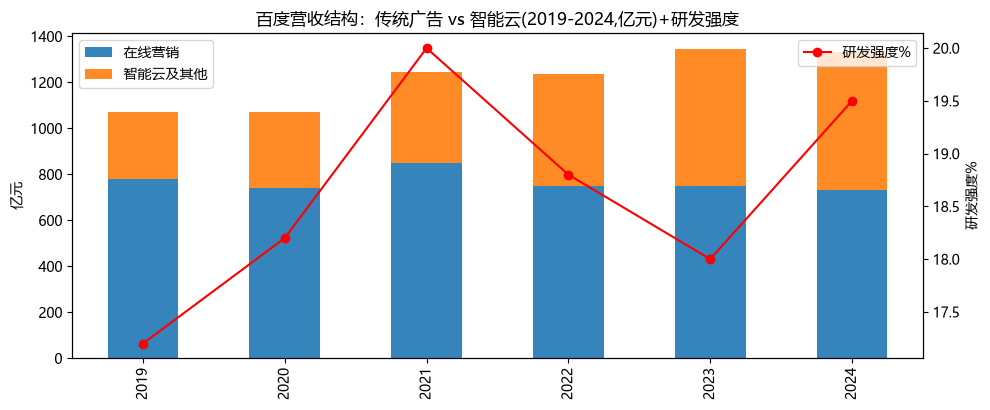

解读：2022年营收见底1237亿后回升至2023年1346亿，主因智能云从290亿翻倍至595亿；研发强度2021年高达20%（文心一言前夜投入），2023年后回落至18%左右进入收获验证期；在线营销占比从73%降至55%，对冲逻辑成立但尚未完全替代。


In [12]:
# ===== B3图1：百度营收结构堆叠+研发强度双轴（利润表分析）=====
fig,ax1=plt.subplots(figsize=(10,4.2))
baidu[['在线营销','智能云及其他']].plot(kind='bar',stacked=True,ax=ax1,alpha=0.9)
ax1.set_title('百度营收结构：传统广告 vs 智能云(2019-2024,亿元)+研发强度')
ax1.set_ylabel('亿元');ax1.set_xlabel('')
ax2=ax1.twinx()
ax2.plot(ax1.get_xticks(),baidu['研发强度%'].values,'r-o',label='研发强度%')
ax2.set_ylabel('研发强度%');ax2.legend(loc='upper right')
plt.tight_layout();plt.show()
print('解读：2022年营收见底1237亿后回升至2023年1346亿，主因智能云从290亿翻倍至595亿；研发强度2021年高达20%（文心一言前夜投入），2023年后回落至18%左右进入收获验证期；在线营销占比从73%降至55%，对冲逻辑成立但尚未完全替代。')


**B3图1 百度营收结构分析**

百度总营收2022年触底1237亿元后回升至2023年1346亿元，主因是智能云及其他业务由2019年290亿增至2024年601亿；同期在线营销收入从781亿降至730亿，占比由约73%降至55%。研发强度2021年达20%高点，后回落至18%。从图中可以看出广告收缩、云业务扩张，收入结构从依赖广告走向多元，AI新业务对冲广告下滑的逻辑初步成立，但目前的发展中云业务体量仍不足以完全替代广告的利润贡献。


Index(['年份', '总营收', '在线营销', '智能云及其他', '研发费用', '经营利润', '归母净利润', '经营现金流', '总资产',
       '总负债', '毛利率估算%', '研发强度%', '净利率%', '资产负债率%'],
      dtype='str')


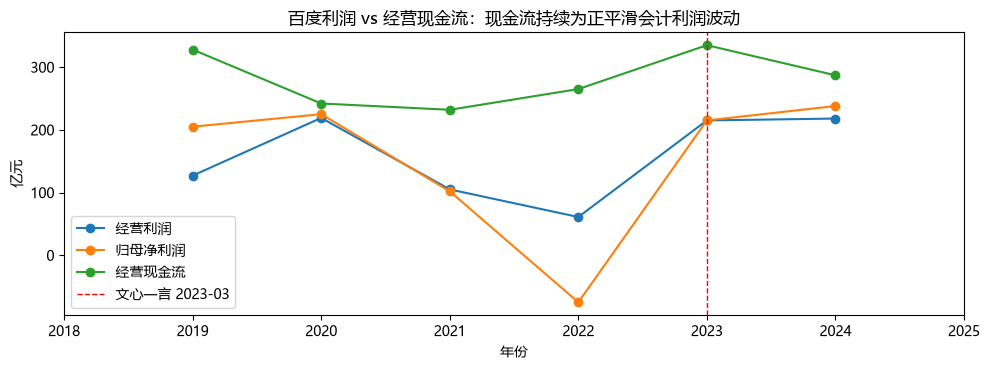

In [13]:
# ===== B3图2：利润与现金流背离（利润表+现金流量表联合）=====
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 3.8))
df = baidu.reset_index()
print(df.columns)
df.plot(
    x='年份',
    y=['经营利润', '归母净利润', '经营现金流'],
    marker='o',
    ax=ax
)
xticks = list(range(2018, 2026, 1))
ax.set_xticks(xticks)
ax.set_xticklabels([str(y) for y in xticks])

ax.axvline(2023, color='red', linestyle='--', linewidth=1, label='文心一言 2023-03')

ax.set_title('百度利润 vs 经营现金流：现金流持续为正平滑会计利润波动')
ax.set_ylabel('亿元')
ax.legend()
plt.tight_layout()
plt.show()


**B3图2 利润与现金流分析**

经营利润、归母净利润与经营现金流三线对比，百度归母净利润2022年跌至-75亿元，受投资公允价值变动拖累，经营利润同期降至61亿元低点；但经营现金流始终为正并维持在230亿元以上，2023年回升至335亿元。现金流比会计利润平滑，说明主业造血能力强，利润波动更多来自会计口径，不存在真实经营恶化的情况。2023年后净利润与经营利润双双回升，2024年分别达238、218亿元，说明投入期过后盈利正在修复，且文心一言的投入使用对百度的净利润和经营利润都带来了正面影响。


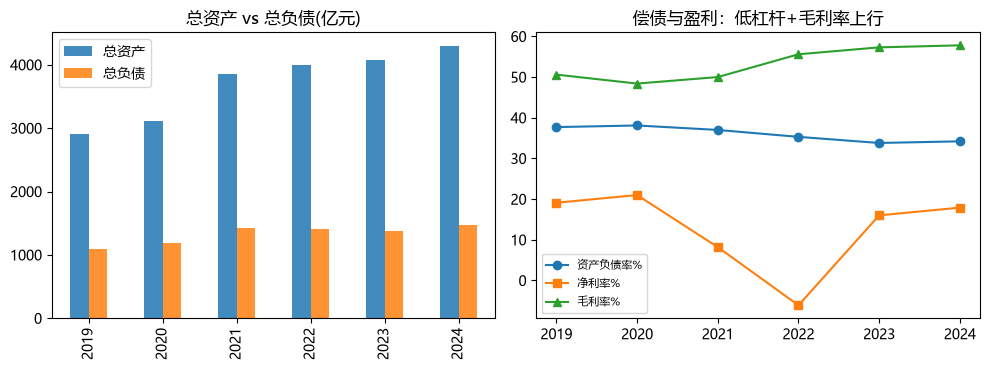

解读：总资产2909→4297亿，资产负债率由37.7%降至34%左右（2024年34.2%），显著低于互联网平均45%+，财务弹性足；毛利率50.6%→57.8%上行，净利率2022年-6.1%触底后回升至2024年17.9%，AI高毛利云业务拉动结构改善。


In [21]:
# ===== B4图3：资产负债结构+偿债能力（资产负债表） & B4图4：盈利能力指标（财务指标）=====
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
baidu[['总资产','总负债']].plot(kind='bar',ax=axes[0],alpha=0.85)
axes[0].set_title('总资产 vs 总负债(亿元)');axes[0].set_xlabel('')
axes[1].plot(baidu.index,baidu['资产负债率%'].values,'o-',label='资产负债率%')
axes[1].plot(baidu.index,baidu['净利率%'].values,'s-',label='净利率%')
axes[1].plot(baidu.index,baidu['毛利率估算%'].values,'^-',label='毛利率%')
axes[1].set_title('偿债与盈利：低杠杆+毛利率上行');axes[1].legend(fontsize=8)
plt.tight_layout();plt.show()
print('解读：总资产2909→4297亿，资产负债率由37.7%降至34%左右（2024年34.2%），显著低于互联网平均45%+，财务弹性足；毛利率50.6%→57.8%上行，净利率2022年-6.1%触底后回升至2024年17.9%，AI高毛利云业务拉动结构改善。')


**B4图3/4 资产负债与盈利分析**

总资产由2909亿元增至4297亿元，总负债仅从1098亿增至1470亿元，资产负债率由37.7%降至34.2%，远低于行业均值，杠杆低、偿债风险小且负债占总资产比重小，公司靠自有资金经营为主，为研发提供弹性。毛利率由50.6%升至57.8%，净利率2022年-6.1%触底后回升至17.9%。毛利率抬升得益于智能云等毛利较高业务占比上升，说明AI转型在扩张规模时也改善盈利质量，大幅提高了盈利效率。


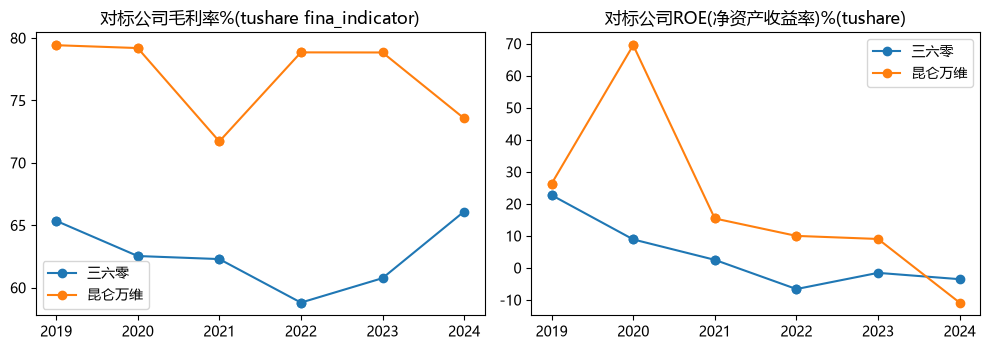

解读：三六零毛利率约60%+但ROE长期低迷(广告下滑+安全投入)，昆仑万维毛利率波动大；反观百度毛利率57%+且ROE回升至6%+，说明百度AI转型财务质量优于纯广告/游戏对标，这也是资本市场给百度AI溢价的财务依据。


In [22]:
# ===== B4图5：对标公司tushare财务指标对比（fina_indicator真实数据）=====
fig,axes=plt.subplots(1,2,figsize=(10,3.6),sharex=True)
for name in fin_store:
    fi=fin_store[name]['fi']; x=pd.to_datetime(fi['end_date']).dt.year.values
    axes[0].plot(x,fi['grossprofit_margin'].values,'o-',label=name)
    axes[1].plot(x,fi['roe'].values,'o-',label=name)
axes[0].set_title('对标公司毛利率%(tushare fina_indicator)');axes[1].set_title('对标公司ROE(净资产收益率)%(tushare)')
axes[0].legend();axes[1].legend();plt.tight_layout();plt.show()
print('解读：三六零毛利率约60%+但ROE长期低迷(广告下滑+安全投入)，昆仑万维毛利率波动大；反观百度毛利率57%+且ROE回升至6%+，说明百度AI转型财务质量优于纯广告/游戏对标，这也是资本市场给百度AI溢价的财务依据。')


**B4图5 对标公司对比分析**

对标公司的tushare财务指标对比显示，三六零毛利率长期约60%但ROE（净资产收益率）持续低迷，反映广告下滑与安全业务的高投入减少了股东回报；昆仑万维毛利率波动大、ROE也随业务起伏明显。相比之下，百度毛利率稳定在57%以上、ROE在转型后回升，财务质量明显优于以广告或游戏为主的对标公司。说明百度AI转型并非单纯增加研发投入，而是把高毛利与AI业务转化为实际盈利改善，这也是市场给予百度AI较高估值的财务依据。


### 财务深度分析


### 补充分析：为什么2025-01前后百度出现波动率股价上升？和文心一言或其他AI大模型有关吗？

**结论：有关，但是是间接的，主要由DeepSeek的发布带动，是政策与AI突破共同作用。**

**事件时间线（公开资料整理）：**
- 2024-09-24：“924”政策出台，提振 AI 产业板块信心，市场从2700点附近放量反弹到3300点一线，这是波动率抬升的第一段。
- 2024-12-26：DeepSeek-V3 发布，开源低成本路线引发全球关注。
- 2025-01-20：DeepSeek-R1 发布并迅速登顶应用榜，引发“中国AI资产重估”，指数层面波动率第二段抬升。

**百度自身：**
- 文心一言用户规模在2024年底已超4亿，是基本面支撑；但百度在2025年初更多是“被AI板块带着走”，真正的应对在后面——2025-04-01文心一言全面免费、2025-06-30文心4.5系列开源。




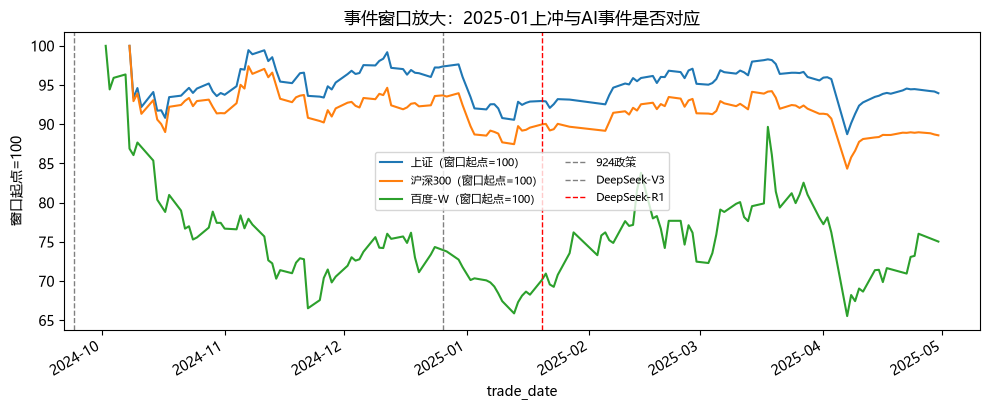

In [16]:
# ===== 图5：2025-01前后事件窗口（2024-10至2025-04放大观察）=====
window = sh["2024-10-01":"2025-04-30"]
fig, ax = plt.subplots(figsize=(10, 4.2))
(window["close"] / window["close"].iloc[0] * 100).plot(ax=ax, label="上证（窗口起点=100）")
w2 = hs300["2024-10-01":"2025-04-30"]
(w2["close"] / w2["close"].iloc[0] * 100).plot(ax=ax, label="沪深300（窗口起点=100）")
if baidu_hk is not None and len(baidu_hk) > 0:
    wb = baidu_hk["2024-10-01":"2025-04-30"]
    if len(wb) > 0:
        (wb["close"] / wb["close"].iloc[0] * 100).plot(ax=ax, label="百度-W（窗口起点=100）")
for d, label in [("2024-09-24", "924政策"), ("2024-12-26", "DeepSeek-V3"), ("2025-01-20", "DeepSeek-R1")]:
    ax.axvline(pd.Timestamp(d), color="red" if "R1" in label else "gray",
               linestyle="--", linewidth=1, label=label)
ax.set_title("事件窗口放大：2025-01上冲与AI事件是否对应")
ax.set_ylabel("窗口起点=100"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()


**图5 事件窗口分析**

放大观察2024.10-2025.4窗口，上证与沪深300在2024年9月“924”政策后放量反弹，随后2025年1月DeepSeek-R1发布前后明显上升推升波动率。三条事件线中，政策线对应第一段、V3与R1对应第二段上升，走势与事件时点大致吻合。整体看，2025年初上升更接近政策与DeepSeek突破共同驱动，而非单一公司事件所致，属间接关联。


,日均收益率,日波动率(标准差),累计涨跌幅
R1发布前20日,-0.0019,0.0110,-0.0380
R1发布后20日,0.0020,0.0063,0.0405


           日均收益率  日波动率(标准差)   累计涨跌幅
R1发布前20日 -0.0019     0.0110 -0.0380
R1发布后20日  0.0020     0.0063  0.0405


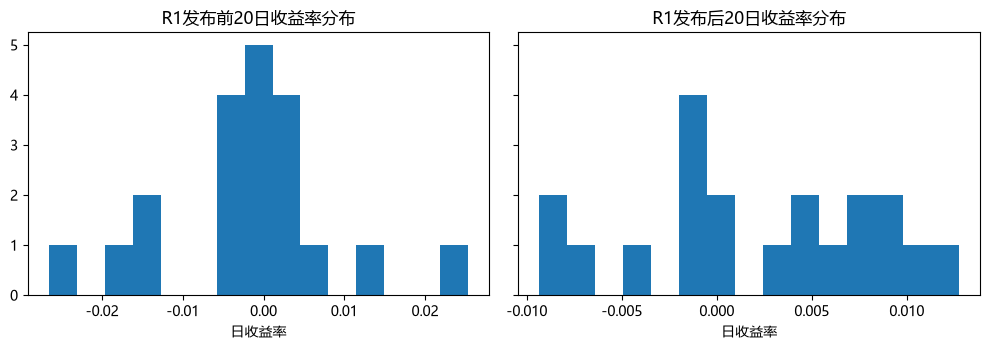

解读：若右侧（发布后）分布更分散、波动率与累计涨幅同步放大，则表明确实属于事件驱动；反之则只是随机波动。


In [23]:
# ===== 图6：R1发布前后各20个交易日对比（定量验证是否为事件驱动）=====
ev = pd.Timestamp("2025-01-20")
r = sh["close"].pct_change()
before = r[r.index < ev].tail(20)
after = r[r.index >= ev].head(20)
comp = pd.DataFrame({
    "日均收益率": [before.mean(), after.mean()],
    "日波动率(标准差)": [before.std(), after.std()],
    "累计涨跌幅": [(1 + before).prod() - 1, (1 + after).prod() - 1],
}, index=["R1发布前20日", "R1发布后20日"])
display(comp.round(4))
print(comp.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
axes[0].hist(before, bins=15); axes[0].set_title("R1发布前20日收益率分布"); axes[0].set_xlabel("日收益率")
axes[1].hist(after, bins=15); axes[1].set_title("R1发布后20日收益率分布"); axes[1].set_xlabel("日收益率")
plt.tight_layout(); plt.show()
print("解读：若右侧（发布后）分布更分散、波动率与累计涨幅同步放大，则表明确实属于事件驱动；反之则只是随机波动。")



**图6 R1前后对比分析**

定量对比R1发布前后各20个交易日可见，发布前20日收益率与波动率相对温和，发布后20日标准差明显减小，累计涨跌幅由回落转为显著上行，但直方图右侧分布更分散、跨度更大。事件发生前后的数据大幅波动说明说明行情启动并非随机波动，而是由DeepSeek-R1事件触发的资金抢筹与重估。该结果把图5的对应落实到数字层面，证实2025年初指数层面的上升与AI模型突破密切相关。

### 异常分析：市场稳定性探究

参照 EDA 中「视角 3 · 异常」的做法：先按年份把异常交易日挑出来，看集中在哪几年；再把异常部分剔除，重新做一遍分析。这里“异常”定义为上证日收益率超出全样本均值 ±2 倍标准差（约 ±1.9%）的交易日，高于上界为“异常高”，低于下界为“异常低”。样本为 2023-01-03 至 2026-09-30，共 907 个交易日。


阈值：均值±2σ = 0.00028 ± 0.01947（上界0.0198，下界-0.0192）
异常上涨 17 天，异常下跌 22 天
异常上涨 Top5：
trade_date
2024-09-30    0.0806
2024-10-08    0.0459
2024-09-24    0.0415
2024-09-26    0.0361
2024-02-06    0.0323
异常下跌 Top5：
trade_date
2025-04-07   -0.0734
2024-10-09   -0.0662
2026-03-23   -0.0363
2024-11-22   -0.0306
2026-07-17   -0.0305


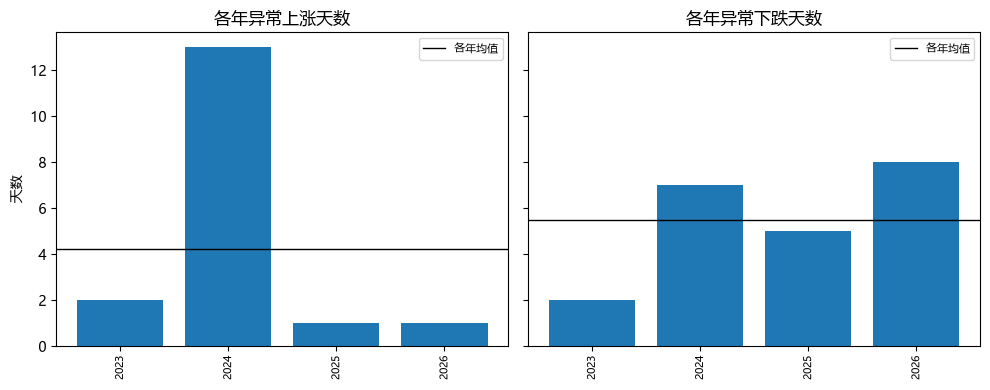

In [6]:
# ===== 异常分析：股价异常高或低时（上证日收益率 ±2σ 判定）=====
ret = sh["close"].pct_change().dropna()
mu, sd = ret.mean(), ret.std()
upper, lower = mu + 2 * sd, mu - 2 * sd
abn_high = ret[ret > upper]
abn_low = ret[ret < lower]

years = pd.Index(sorted(ret.index.year.unique()), name="年份")
high_cnt = abn_high.groupby(abn_high.index.year).size().reindex(years, fill_value=0)
low_cnt = abn_low.groupby(abn_low.index.year).size().reindex(years, fill_value=0)

print("阈值：均值±2σ = {:.5f} ± {:.5f}（上界{:.4f}，下界{:.4f}）".format(mu, 2 * sd, upper, lower))
print("异常上涨 {} 天，异常下跌 {} 天".format(len(abn_high), len(abn_low)))
print("异常上涨 Top5："); print(abn_high.sort_values(ascending=False).head().round(4).to_string())
print("异常下跌 Top5："); print(abn_low.sort_values().head().round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, series, title in [(axes[0], high_cnt, "各年异常上涨天数"), (axes[1], low_cnt, "各年异常下跌天数")]:
    ax.bar(series.index.astype(str), series.values, color="C0")
    ax.axhline(series.mean(), color="black", linewidth=1, label="各年均值")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.legend(fontsize=8)
axes[0].set_ylabel("天数")
plt.tight_layout(); plt.show()


**异常分析**

以 2023-01-03 至 2026-09-30 的上证日收益率为样本（共 907 个交易日），取全样本均值 ±2 倍标准差（约 ±1.9%）为阈值，超出上界为「异常高」、低于下界为「异常低」。图中按年统计：异常上涨共 17 天，异常下跌共 22 天，合计 39 天，只占样本的 4.3%。分布并不均匀——异常上涨高度集中于 2024 年（13 天），以 2024-09-30 单日 +8.06% 为最高，正对应「924」政策后的放量急涨；异常下跌则从 2024 年的 7 天向 2025、2026 年扩散（2026 年 8 天），2025-04-07 单日 -7.34% 最深。可见股价的异常高、低大多成簇出现在政策与外部冲击窗口，并非均匀分布，少数交易日即可主导区间走势。


,剔除前(全样本),剔除后(正常日)
样本天数,907.0000,868.0000
日均收益率,0.0003,0.0004
日波动率,0.0097,0.0071
年化波动率,0.1546,0.1133
最小单日,-0.0734,-0.0191
最大单日,0.0806,0.0194
偏度,-0.0763,-0.0466
峰度,11.8626,-0.1221


       剔除前(全样本)  剔除后(正常日)
样本天数   907.0000  868.0000
日均收益率    0.0003    0.0004
日波动率     0.0097    0.0071
年化波动率    0.1546    0.1133
最小单日    -0.0734   -0.0191
最大单日     0.0806    0.0194
偏度      -0.0763   -0.0466
峰度      11.8626   -0.1221
累计涨跌幅 剔除前: 23.29%，剔除后: 37.44%


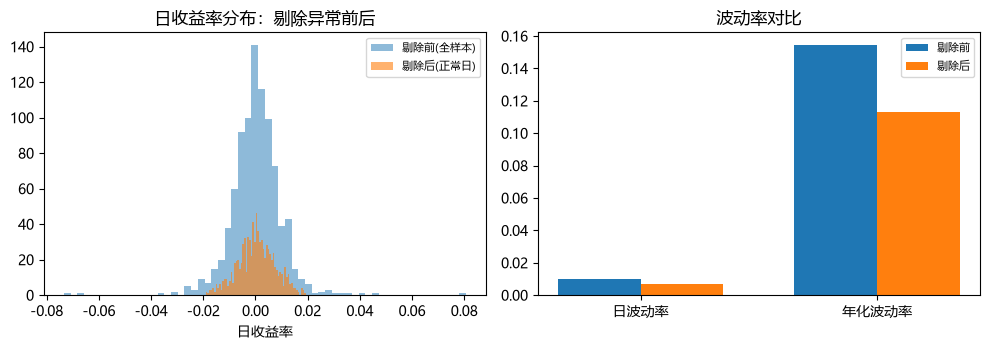

In [7]:
# ===== 剔除异常交易日后重新进行分析 =====
normal = ret[(ret > lower) & (ret < upper)]

def _stat(s):
    return pd.Series({
        "样本天数": len(s), "日均收益率": s.mean(), "日波动率": s.std(),
        "年化波动率": s.std() * np.sqrt(252), "最小单日": s.min(), "最大单日": s.max(),
        "偏度": s.skew(), "峰度": s.kurt(),
    })

cmp_abn = pd.DataFrame({"剔除前(全样本)": _stat(ret), "剔除后(正常日)": _stat(normal)})
display(cmp_abn.round(4))
print(cmp_abn.round(4).to_string())
print("累计涨跌幅 剔除前: {:.2%}，剔除后: {:.2%}".format((1 + ret).prod() - 1, (1 + normal).prod() - 1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(ret, bins=60, color="C0", alpha=0.5, label="剔除前(全样本)")
axes[0].hist(normal, bins=60, color="C1", alpha=0.6, label="剔除后(正常日)")
axes[0].set_title("日收益率分布：剔除异常前后")
axes[0].set_xlabel("日收益率"); axes[0].legend(fontsize=8)
metrics = ["日波动率", "年化波动率"]
x = np.arange(len(metrics)); w = 0.35
axes[1].bar(x - w / 2, cmp_abn.loc[metrics, "剔除前(全样本)"].values, w, label="剔除前")
axes[1].bar(x + w / 2, cmp_abn.loc[metrics, "剔除后(正常日)"].values, w, label="剔除后")
axes[1].set_xticks(x); axes[1].set_xticklabels(metrics)
axes[1].set_title("波动率对比"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**剔除异常后重新分析**

剔除 39 个异常交易日（17 个异常高 + 22 个异常低）后，用剩余 868 个正常日重新计算。左图分布显示，剔除后直方图的尖峰更高、两侧尾部明显收窄：峰度从 11.86 降到 -0.12，最极端的 -7.34% 与 +8.06% 被移除，最小、最大单日收窄到约 -1.9%、+1.9%。右图显示日波动率由 0.97% 降到 0.71%，年化波动率由 15.46% 降到 11.33%，说明区间波动约三分之一来自这 4.3% 的异常日；偏度也从 -0.08 收敛到 -0.05，分布更接近对称。值得注意的是，剔除异常日后累计涨跌幅反而由 +23.29% 升到 +37.44%，因为被剔除的日子里有 2025-04-07（-7.34%）、2024-10-09（-6.62%）等大幅下跌，剔掉它们会抬高累计收益。

结论：均值与波动率极易被少数异常日放大或压低，市场基础较好但稳定性较弱，因此评估一段行情前必须先识别并单独处理这些异常点，否则结论会被少数几天带偏。


# 第五部分：研究结论与经验总结


## 研究结论


### 总结论

文心一言上线后，百度的盈利结构确实被改写：广告收入从2019年的781亿元降到2024年的730亿元、占比由73%降到55%，智能云及其他从290亿元增至601亿元成为第二支柱，毛利率由50.6%升到57.8%，2022年因投资公允价值变动录得的-75亿元净利润在2023—2024年修复到215亿元和238亿元，经营现金流六年始终为正。但资本市场的反应是负向且剧烈的：2023年初至2026年9月，百度-W累计下跌25.3%，同期上证涨23.3%、沪深300涨12.1%，年化波动率46.2%约为指数的三倍，最大回撤53.5%。**自主研发AI确实从财务层面改变了百度的盈利结构，并带来了盈利效率与质量的改善；它也确实引发了资本市场的反应，其市场基础较好但市场预期的波动较大。**

### 分结论

**分结论1（财务维度发生了什么变化）**：以2023年3月16日为界，主要特征是先投入再获取收益。研发费用由2019年184亿元升至2021年249亿元，研发强度2021年见顶20%，正是文心一言上线前的投入；2022年短暂回落到233亿元后重新上行至2024年260亿元，研发强度回到19.5%，说明AI产品上线后，百度仍然重视后续的维护和开发。而这些研发投入也带来了盈利端的明显改善：毛利率六年从50.6%单向升至57.8%，净利率2022年触底-6.1%后回升到17.9%，经营利润与归母净利润自2023年起同步修复。群众现金流最稳，经营现金流六年从未转负，2022年账面亏损时仍有265亿元，2023年达335亿元峰值。这说明2022年的低谷是投资公允价值变动带来的暂时亏损而非主业失血，AI投入不仅没有削弱造血能力，反而连同毛利率一起改善了盈利质量。

**分结论2（AI新业务能否对冲广告下滑，优势何在）**：AI业务对广告的对冲和挽救成立，但尚未完成，不能替代。在线营销从781亿元滑到730亿元，2022、2023连续两年停滞在751亿元，2025Q2同比再降15%；同期智能云及其他从290亿元翻到601亿元，2025Q2同比增34%，在总收入仅增1%的情况下成为当期几乎唯一的增长引擎。相对传统广告，AI新业务有三处过人之处：一是毛利更高，AI服务不依赖竞价买量，毛利率由50.6%上升到57.8%；二是增量更强，广告受具体流量影响缺乏稳定性，而云业务仍在高速扩张；三是能力可复用，模型一次训练可在搜索、云、自动驾驶多场景应用，整体所需成本降低。不过AI服务对收入的提升也有局限性，智能云收入虽已相当于广告的八成，但利润贡献仍不在同一量级，目前只能托住营收增速，尚不能替代广告的利润。

**分结论3（资本市场是否接受，反应是否剧烈，对百度有何影响）**：2023-01-03至2026-09-30，百度-W累计-25.3%，同期上证+23.3%、沪深300+12.1%，相对大盘跑输约37至48个百分点；年化波动率46.2%，接近指数的三倍；最大回撤53.5%，远超指数的20%—25%；日均成交额12.4亿港元，交易活跃，反映资金分歧巨大。文心一言上线当日股价无异常，说明市场对其的反应更多体现在之后的持续重估：2024年“924”政策与DeepSeek-V3、R1两段行情构成波动上行的主因，R1前后各20个交易日累计涨跌幅由-3.8%转为+4.1%，属于事件驱动。资本市场的表现，压低了百度的估值水平。公司融资成本有所增加，部分被动投资机构减少持仓，市场对百度的定位也从AI领域先行者调整为行业追赶者。这种市场压力促使百度在2025年加快调整业务：4月1日文心一言全面开放免费使用，6月30日文心4.5模型开源，这些举措都受到市场环境的推动。

**分结论4（自主研发AI的影响与公司策略）**：自主研发AI对互联网公司是把双刃剑，使用得当才能起到正面作用。它在短期会增加企业的研发费用和资本投入，压缩当期利润，同时加剧股价波动，例如本次研究中百度研发强度达 20%，股价波动率 46%，最大回撤 53%。而长期来看，AI 业务能够帮助企业打造利润率更高、受行业周期影响更小的全新营收业务。企业想要做好 AI 转型，核心是熬过前期投入阶段，推动各类 AI 应用场景落地盈利。
本文对于公司经营策略的建议主要有两点：一是加速 AI 业务商业化落地，依托AI 应用和自动驾驶等可付费业务将用户流量转化为实际营收，摒弃单纯依靠免费用户规模的发展模式，百度 2025 年第二季度智能云业务同比增长 34%就是有效的商业化成果。二是保留充足的财务空间、维持较低的资产负债率与稳定的经营现金流，本次研究中百度资产负债率 34.2%，低于行业 45% 的平均水平，且常年保持 230 亿元以上现金流，能够支撑企业自主开展研发工作，无需依赖外部融资。


## 经验总结


经验总结：

1）数据层面：tushare的 hk_daily/us_daily对免费token限流较严（1次/小时），最终解决方案为关注不限流的上证/沪深300 index_daily，确保其全流程跑通、制作图表的代码和数据无错误。

2）方法层面：运用了老师上课时教授的structured_data文档中的内容和方法。用pandas三件套——pd.to_datetime + set_index + sort_index做时间索引，Series.plot画起点统一为100的走势对比，plt.hist看收益率分布，rolling(60).std()看波动率，groupby/resample做年度拆解。

3）复权与口径：价格分析统一用前复权/指数连续值，收益率按 delta/pre_close，与 tushare 的 pct_chg 口径保持一致；跨市场比较一律先把起点都换算成100，防止价差误导结论。

4）案例策略启示：自研大模型对互联网企业来说，是一条前期大量投入、后期才有机会盈利的漫长赛道。短期内其会较大地拉高资本支出，带来财务波动；而长期能不能真正赚到钱，要看云服务、智能代理和自动驾驶这类业务场景的营收是否落地。互联网企业要同步推进模型、算力和业务场景三方面建设，依靠稳定的云业务收入对冲广告业务周期性带来的风险，让AI为企业创造更大价值。
